# patch stithing error
projecting down the results fromm 3 to 1 dimension using PCA. Then correlating the result with the individual input variables.

1. load model
2. load dataset patches
3. predict results using NOFE and other methods
4. stitch results together + plot
5. quantitative evaluation based on neighbors across patches

---
### Utilities

In [1]:
import sys
import json
import random
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import napari
from scipy.interpolate import griddata
from pathlib import Path

from plot_utils_era5 import *

project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(Path.cwd().parent / 'scripts'))

sys.path.append(f"{project_root}src/")
# Import utilities
from utilities import KernelNN, KernelNN_subgraph, GraphLMDBReader, setup_device, get_output_affinities
from plot_utilities import plot_results_napari, plot_results_matplotlib

sys.path.append(f"{project_root}/ERA5/scripts/")
from utilities_era5 import ERA5_Graph_Generator as Data_Generator
from utilities_era5 import ERA5_Graph_Generator_perSampleNorm as Data_Generator_old
data_path = project_root / 'ERA5' / 'data'

# Device setup
device = setup_device()
print(f'Using device: {device}')

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import subprocess

from scipy.spatial import cKDTree

def load_model(id:str, model_type:str='random_crop'):
    model_path = project_root / 'ERA5' / 'trained_models' / model_type / f'{id}.pth'
    config_path = project_root / 'ERA5' / 'trained_models' / model_type / 'logs' / 'configs' / f'{id}.json' 
    
    with open(config_path, 'r') as f:
        config = json.load(f)
    
    model = KernelNN(
        width=config['width'],
        ker_width=config['ker_width'],
        depth=config['depth'],
        ker_in=config['edge_attr'],
        in_width=config['node_features'],
        out_width=config['out_width']
    ).to(device)
    
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    
    return model, config

using Device: mps
Using device: mps


----
### load model + dataset 

In [2]:
model, config = load_model(id='test1_model5_median_tkernel_2026-04-22_t21-22-37' , model_type='regular')

In [3]:
lat_min = config["lat_min"]
lat_max = config["lat_max"]
lon_min = config["lon_min"]
lon_max = config["lon_max"]
#N = config["N"]
k = config["k"]
perplexity = config["perplexity"]
sampling_method = config["sampling_method"]
train_date_start_end = config["train_date_start_end"]
test_date_start_end = config["test_date_start_end"]
train_samples_per_date = config["train_samples_per_date"]
test_samples_per_date = config["test_samples_per_date"]
feature_mode = config["feature_mode"]
vars = config["vars"]


In [4]:
lat_range = (lat_max - lat_min)/2
lon_range = (lon_max - lon_min)/2
margin=5
'''
bbox1 = lon_min, lat_min+lat_range-margin, lon_max-lon_range+margin, lat_max
bbox2 = lon_min+lon_range-margin, lat_min+lat_range-margin, lon_max, lat_max
bbox3 = lon_min, lat_min, lon_max-lon_range+margin, lat_max-lat_range+margin
bbox4 = lon_min+lon_range-margin, lat_min, lon_max, lat_max-lat_range+margin

bboxes = [bbox1, bbox2, bbox3, bbox4]
'''
bbox1 = lon_min, lat_min, lon_max-lon_range+margin, lat_max
bbox2 = lon_min+lon_range-margin, lat_min, lon_max, lat_max
bboxes = [bbox1, bbox2]

In [5]:
date = "2019-01-10"

#Generator = Data_Generator_old(data_path)
Generator = Data_Generator(data_path)

N=10000
print('generate data')

graphs=[]
locations_list=[]
X_list=[]

for bbox in bboxes:
    Generator.load_data(bbox=bbox, vars=vars, filename=f'{date}.nc')
    print(f'total points available: {Generator.da.shape[1]*Generator.da.shape[2]}')
    graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method, gen_feature_mode=feature_mode, sigma_method='ones')
    sample = graph.to(device)
    graphs.append(sample)
    locations_list.append(pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]}))
    X_list.append(sample.normed_values.detach().cpu().numpy())

generate data
total points available: 20091
total points available: 20091


---
## Get Predictions

In [6]:
pred_nofe_list = []
pred_pca_list = []
pred_tsne_list = []
pred_umap_list = []

for sample in graphs:
    # NOFE
    print('NOFE ...', end='\r')
    pred_nofe = model(sample).detach().cpu().numpy()
    pred_nofe_list.append(pred_nofe)
    
    X = sample.normed_values.detach().cpu().numpy()
    
    # PCA
    print('PCA ...', end='\r')
    pca = PCA(n_components=3)
    pred_pca = pca.fit_transform(X)
    pred_pca_list.append(pred_pca)

    # t-SNE
    print('t-SNE ...', end='\r')
    pred_tsne = TSNE(
        n_components=3,
        perplexity=30,
        learning_rate="auto",
        random_state=42
    ).fit_transform(X)
    pred_tsne_list.append(pred_tsne)

    # UMAP
    print('UMAP ...', end='\r')
    umap_id = 'umap_buffer'
    dir = f'{project_root}/ERA5/umap'
    np.save(f'{dir}/{umap_id}.npy', X)
    subprocess.run(f"cd {dir} && conda run -n umap python execute_umap.py {umap_id}", shell=True)
    pred_umap = np.load(f'{dir}/res_{umap_id}.npy')
    pred_umap_list.append(pred_umap)

    os.remove(f'{dir}/{umap_id}.npy')
    os.remove(f'{dir}/res_{umap_id}.npy')


importing libraries
reading in data
applying umap
saving file
"
file saved as res_umap_buffer.npy"



/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")



importing libraries
reading in data
applying umap
saving file
"
file saved as res_umap_buffer.npy"



/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")



# Plot

In [7]:
locations = pd.DataFrame(np.vstack(locations_list), columns=['lat', 'lon'])

pred_nofe_combined = pd.DataFrame(np.vstack(pred_nofe_list), columns=['x1', 'x2', 'x3'])
pred_nofe_combined = pd.concat([locations, pred_nofe_combined], axis=1)

pred_pca_combined = pd.DataFrame(np.vstack(pred_pca_list), columns=['x1', 'x2', 'x3'])
pred_pca_combined = pd.concat([locations, pred_pca_combined], axis=1)

pred_tsne_combined = pd.DataFrame(np.vstack(pred_tsne_list), columns=['x1', 'x2', 'x3'])
pred_tsne_combined = pd.concat([locations, pred_tsne_combined], axis=1)

pred_umap_combined = pd.DataFrame(np.vstack(pred_umap_list), columns=['x1', 'x2', 'x3'])
pred_umap_combined = pd.concat([locations, pred_umap_combined], axis=1)




Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0739959108897437..1.0047462016505777].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0015524496184065976..1.0313559482678145].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.134576611292393..1.1747192239282866].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.4882125853523884..1.2951945916495193].


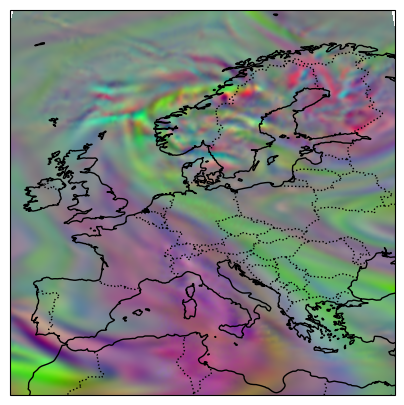

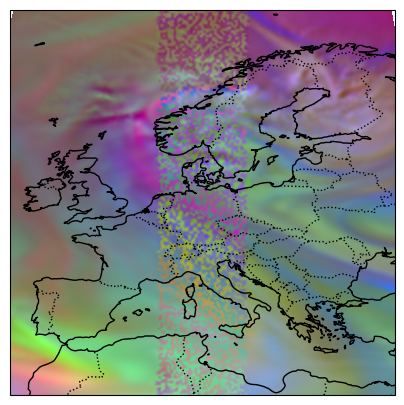

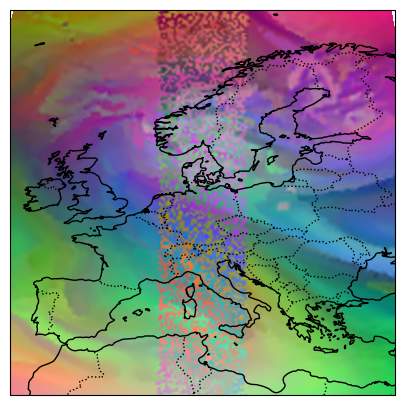

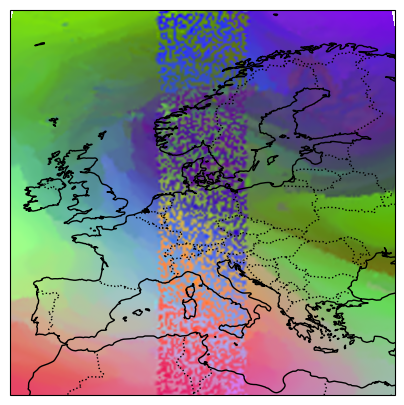

In [8]:
figsize=(5,5)
fig_nofe = rgb(pred_nofe_combined, figsize=figsize)
fig_pca = rgb(pred_pca_combined, figsize=figsize)
fig_tsne = rgb(pred_tsne_combined, figsize=figsize)
fig_umap = rgb(pred_umap_combined, figsize=figsize)

# Quantitative Evaluation

In [ ]:
dates = pd.date_range("2019-01-01", "2019-01-31").strftime("%Y-%m-%d").tolist()

#Generator = Data_Generator_old(data_path)
Generator = Data_Generator(data_path)

N=1000

edge_margin = 2

print('generate data')

for date in dates:
    # ==================== Generate Data ====================
    graphs=[]
    locations_list=[]
    X_list=[]
    
    for bbox in bboxes:
        Generator.load_data(bbox=bbox, vars=vars, filename=f'{date}.nc')
        print(f'total points available: {Generator.da.shape[1]*Generator.da.shape[2]}')
        graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method, gen_feature_mode=feature_mode, sigma_method='ones')
        sample = graph.to(device)
        graphs.append(sample)
        locations_list.append(pd.DataFrame({"lat": sample.meta.gps[:,0], "lon": sample.meta.gps[:,1]}))
        X_list.append(sample.normed_values.detach().cpu().numpy())
        
    # ==================== Predict ====================
    pred_nofe_list = []
    pred_pca_list = []
    pred_tsne_list = []
    pred_umap_list = []

    for sample in graphs:
        # NOFE
        print('NOFE ...', end='\r')
        pred_nofe = model(sample).detach().cpu().numpy()
        pred_nofe_list.append(pred_nofe)
        
        X = sample.normed_values.detach().cpu().numpy()
        
        # PCA
        print('PCA ...', end='\r')
        pca = PCA(n_components=3)
        pred_pca = pca.fit_transform(X)
        pred_pca_list.append(pred_pca)

        # t-SNE
        print('t-SNE ...', end='\r')
        pred_tsne = TSNE(
            n_components=3,
            perplexity=30,
            learning_rate="auto",
            random_state=42
        ).fit_transform(X)
        pred_tsne_list.append(pred_tsne)

        # UMAP
        print('UMAP ...', end='\r')
        umap_id = 'umap_buffer'
        dir = f'{project_root}/ERA5/umap'
        np.save(f'{dir}/{umap_id}.npy', X)
        subprocess.run(f"cd {dir} && conda run -n umap python execute_umap.py {umap_id}", shell=True)
        pred_umap = np.load(f'{dir}/res_{umap_id}.npy')
        pred_umap_list.append(pred_umap)

        os.remove(f'{dir}/{umap_id}.npy')
        os.remove(f'{dir}/res_{umap_id}.npy')
    
    # ==================== get indices ====================
    idx12 = np.where(graphs[0].meta.gps[:,1] > (bbox1[2]-edge_margin))[0]
    idx21 = np.where(graphs[1].meta.gps[:,1] < (bbox2[0]+edge_margin))[0]

    idx13 = np.where(graphs[0].meta.gps[:,0] < (bbox1[1]+edge_margin))[0]
    idx31 = np.where(graphs[2].meta.gps[:,0] > (bbox3[3]-edge_margin))[0]

    idx24 = np.where(graphs[1].meta.gps[:,0] < (bbox2[1]+edge_margin))[0]
    idx42 = np.where(graphs[3].meta.gps[:,0] > (bbox4[3]-edge_margin))[0]

    idx34 = np.where(graphs[2].meta.gps[:,1] > (bbox3[2]-edge_margin))[0]
    idx43 = np.where(graphs[3].meta.gps[:,1] < (bbox4[0]+edge_margin))[0]

    edge_idx_pairs = [(idx12, idx21), (idx13,idx31), (idx24,idx42), (idx34,idx43)]
    edge_subset_pairs = [(0, 1), (0,2), (1,3), (2,3)]
    
    
    
stitching_errors_nofe = []
stitching_errors_pca = []
stitching_errors_tsne = []
stitching_errors_umap = []


def mean_dist(x):
    N = x.shape[0]
    dists = torch.cdist(x, x)
    mean_dist = dists.triu(diagonal=1).sum() / (N * (N - 1) / 2)
    return mean_dist


for method_id in range(4):
    # set output_data to list of corresponding predictions, containing 4 individual results, one per region
    if methods[method_id] == 'nofe':
        output_data = pred_nofe_list
    elif methods[method_id] == 'pca':
        output_data = pred_pca_list
    elif methods[method_id] == 'tsne':
        output_data = pred_tsne_list
    elif methods[method_id] == 'umap':
        output_data = pred_umap_list
        
    normed_distance_tensors = []
    
    # iterating through region borders 
    for i in range(4):
        
        # ============ first from patch A to B ===================
        
        # set a, b to indices to select the two patches that we want to compare
        a = edge_subset_pairs[i][0] 
        b = edge_subset_pairs[i][1]
        # set a_idx, b_idx to list of node indices within a patch, to select nodes that are in the border region to the neighboring patch
        a_idx = edge_idx_pairs[i][0]
        b_idx = edge_idx_pairs[i][1]
        
        # select subgraph according to patch and subset of nodes within the graph according to border region
        coords_a = graphs[a].normed_coords[a_idx,:].detach().cpu().numpy()
        coords_b = graphs[b].normed_coords[b_idx,:].detach().cpu().numpy()
        
        # find nearest neighbor in patch b for each node in patch a
        tree_a = cKDTree(coords_b)
        distances_a, indices_a = tree_a.query(coords_a)
        
        # set A to actual feature values of nodes in patch A, then subset to border region
        A = torch.from_numpy(output_data[a][a_idx])
        # set B to feature values of nodes in patch B, then subset to border region, then iterate through indices according to neighborhood search
        B = torch.from_numpy(output_data[b][b_idx][indices_a])
        normalization = mean_dist(A)
        normed_dist = torch.norm(A - B, dim=1)/normalization
        normed_distance_tensors.append(normed_dist)
        
        
        
        # ============ then from patch B to A ===================
        
        # set a, b to indices to select the two patches that we want to compare
        a = edge_subset_pairs[i][0] 
        b = edge_subset_pairs[i][1]
        # set a_idx, b_idx to list of node indices within a patch, to select nodes that are in the border region to the neighboring patch
        a_idx = edge_idx_pairs[i][0]
        b_idx = edge_idx_pairs[i][1]
        
        # select subgraph according to patch and subset of nodes within the graph according to border region
        coords_a = graphs[a].normed_coords[a_idx,:].detach().cpu().numpy()
        coords_b = graphs[b].normed_coords[b_idx,:].detach().cpu().numpy()
        
        # find nearest neighbor in patch a for each node in patch b
        tree_b = cKDTree(coords_a)
        distances_b, indices_b = tree_b.query(coords_b)
        
        # set A to actual feature values of nodes in patch A, then subset to border region
        B = torch.from_numpy(output_data[b][b_idx])
        # set B to feature values of nodes in patch B, then subset to border region, then iterate through indices according to neighborhood search
        A = torch.from_numpy(output_data[a][a_idx][indices_b])
        normalization = mean_dist(B)
        normed_dist = torch.norm(B-A, dim=1)/normalization
        normed_distance_tensors.append(normed_dist)

    normed_distances = torch.hstack(normed_distance_tensors)
    avg_normed_dist = normed_distances.mean()
    print(f'{methods[method_id]}: {avg_normed_dist}')
    
    if methods[method_id] == 'nofe':
        stitching_errors_nofe = normed_distances
    elif methods[method_id] == 'pca':
        stitching_errors_pca = normed_distances
    elif methods[method_id] == 'tsne':
        stitching_errors_tsne = normed_distances
    elif methods[method_id] == 'umap':
        stitching_errors_umap = normed_distances

generate data
total points available: 8281
total points available: 8281
total points available: 8281
total points available: 8281


In [216]:
pred_nofe_list = []
pred_pca_list = []
pred_tsne_list = []
pred_umap_list = []

for sample in graphs:
    # NOFE
    print('NOFE ...', end='\r')
    pred_nofe = model(sample).detach().cpu().numpy()
    pred_nofe_list.append(pred_nofe)
    
    X = sample.normed_values.detach().cpu().numpy()
    
    # PCA
    print('PCA ...', end='\r')
    pca = PCA(n_components=3)
    pred_pca = pca.fit_transform(X)
    pred_pca_list.append(pred_pca)

    # t-SNE
    print('t-SNE ...', end='\r')
    pred_tsne = TSNE(
        n_components=3,
        perplexity=30,
        learning_rate="auto",
        random_state=42
    ).fit_transform(X)
    pred_tsne_list.append(pred_tsne)

    # UMAP
    print('UMAP ...', end='\r')
    umap_id = 'umap_buffer'
    dir = f'{project_root}/ERA5/umap'
    np.save(f'{dir}/{umap_id}.npy', X)
    subprocess.run(f"cd {dir} && conda run -n umap python execute_umap.py {umap_id}", shell=True)
    pred_umap = np.load(f'{dir}/res_{umap_id}.npy')
    pred_umap_list.append(pred_umap)

    os.remove(f'{dir}/{umap_id}.npy')
    os.remove(f'{dir}/res_{umap_id}.npy')


importing libraries
reading in data
applying umap
saving file
"
file saved as res_umap_buffer.npy"



/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")



importing libraries
reading in data
applying umap
saving file
"
file saved as res_umap_buffer.npy"



/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")



importing libraries
reading in data
applying umap
saving file
"
file saved as res_umap_buffer.npy"



/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")



importing libraries
reading in data
applying umap
saving file
"
file saved as res_umap_buffer.npy"



/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/Users/laueb4818/miniforge3/envs/umap/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")



In [217]:
edge_margin = 2

idx12 = np.where(graphs[0].meta.gps[:,1] > (bbox1[2]-edge_margin))[0]
idx21 = np.where(graphs[1].meta.gps[:,1] < (bbox2[0]+edge_margin))[0]

idx13 = np.where(graphs[0].meta.gps[:,0] < (bbox1[1]+edge_margin))[0]
idx31 = np.where(graphs[2].meta.gps[:,0] > (bbox3[3]-edge_margin))[0]

idx24 = np.where(graphs[1].meta.gps[:,0] < (bbox2[1]+edge_margin))[0]
idx42 = np.where(graphs[3].meta.gps[:,0] > (bbox4[3]-edge_margin))[0]

idx34 = np.where(graphs[2].meta.gps[:,1] > (bbox3[2]-edge_margin))[0]
idx43 = np.where(graphs[3].meta.gps[:,1] < (bbox4[0]+edge_margin))[0]

edge_idx_pairs = [(idx12, idx21), (idx13,idx31), (idx24,idx42), (idx34,idx43)]
edge_subset_pairs = [(0, 1), (0,2), (1,3), (2,3)]

In [218]:
#
methods=['nofe', 'pca', 'tsne', 'umap']

stitching_errors_nofe = []
stitching_errors_pca = []
stitching_errors_tsne = []
stitching_errors_umap = []


def mean_dist(x):
    N = x.shape[0]
    dists = torch.cdist(x, x)
    mean_dist = dists.triu(diagonal=1).sum() / (N * (N - 1) / 2)
    return mean_dist


for method_id in range(4):
    # set output_data to list of corresponding predictions, containing 4 individual results, one per region
    if methods[method_id] == 'nofe':
        output_data = pred_nofe_list
    elif methods[method_id] == 'pca':
        output_data = pred_pca_list
    elif methods[method_id] == 'tsne':
        output_data = pred_tsne_list
    elif methods[method_id] == 'umap':
        output_data = pred_umap_list
        
    normed_distance_tensors = []
    
    # iterating through region borders 
    for i in range(4):
        
        # ============ first from patch A to B ===================
        
        # set a, b to indices to select the two patches that we want to compare
        a = edge_subset_pairs[i][0] 
        b = edge_subset_pairs[i][1]
        # set a_idx, b_idx to list of node indices within a patch, to select nodes that are in the border region to the neighboring patch
        a_idx = edge_idx_pairs[i][0]
        b_idx = edge_idx_pairs[i][1]
        
        # select subgraph according to patch and subset of nodes within the graph according to border region
        coords_a = graphs[a].normed_coords[a_idx,:].detach().cpu().numpy()
        coords_b = graphs[b].normed_coords[b_idx,:].detach().cpu().numpy()
        
        # find nearest neighbor in patch b for each node in patch a
        tree_a = cKDTree(coords_b)
        distances_a, indices_a = tree_a.query(coords_a)
        
        # set A to actual feature values of nodes in patch A, then subset to border region
        A = torch.from_numpy(output_data[a][a_idx])
        # set B to feature values of nodes in patch B, then subset to border region, then iterate through indices according to neighborhood search
        B = torch.from_numpy(output_data[b][b_idx][indices_a])
        normalization = mean_dist(A)
        normed_dist = torch.norm(A - B, dim=1)/normalization
        normed_distance_tensors.append(normed_dist)
        
        
        
        # ============ then from patch B to A ===================
        
        # set a, b to indices to select the two patches that we want to compare
        a = edge_subset_pairs[i][0] 
        b = edge_subset_pairs[i][1]
        # set a_idx, b_idx to list of node indices within a patch, to select nodes that are in the border region to the neighboring patch
        a_idx = edge_idx_pairs[i][0]
        b_idx = edge_idx_pairs[i][1]
        
        # select subgraph according to patch and subset of nodes within the graph according to border region
        coords_a = graphs[a].normed_coords[a_idx,:].detach().cpu().numpy()
        coords_b = graphs[b].normed_coords[b_idx,:].detach().cpu().numpy()
        
        # find nearest neighbor in patch a for each node in patch b
        tree_b = cKDTree(coords_a)
        distances_b, indices_b = tree_b.query(coords_b)
        
        # set A to actual feature values of nodes in patch A, then subset to border region
        B = torch.from_numpy(output_data[b][b_idx])
        # set B to feature values of nodes in patch B, then subset to border region, then iterate through indices according to neighborhood search
        A = torch.from_numpy(output_data[a][a_idx][indices_b])
        normalization = mean_dist(B)
        normed_dist = torch.norm(B-A, dim=1)/normalization
        normed_distance_tensors.append(normed_dist)

    normed_distances = torch.hstack(normed_distance_tensors)
    avg_normed_dist = normed_distances.mean()
    print(f'{methods[method_id]}: {avg_normed_dist}')
    
    if methods[method_id] == 'nofe':
        stitching_errors_nofe = normed_distances
    elif methods[method_id] == 'pca':
        stitching_errors_pca = normed_distances
    elif methods[method_id] == 'tsne':
        stitching_errors_tsne = normed_distances
    elif methods[method_id] == 'umap':
        stitching_errors_umap = normed_distances

nofe: 1.0348153114318848
pca: 1.5500853061676025
tsne: 1.5700730085372925
umap: 1.96963369846344


In [ ]:
nofe: 1.0652854442596436
pca: 1.5943142175674438
tsne: 1.6227450370788574
umap: 2.747061014175415